# 09 Visualisation
The broken-skull workflow on held-out test skulls: the hidden bone, the most likely face, where it is certain, four plausible faces, and the
regions ranked from most to least certain. Millimetre scales are labelled. The interactive version is the demo page. Faces are synthetic.

In [1]:
import sys, pathlib, os, json
ROOT = pathlib.Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
REAL, RUN, RES = 'UNCERTAFACE_DATA_REAL', 'experiments/runs/face_v3_pn', 'reports/results/face_v3_pn'
if not pathlib.Path(REAL).exists():
    raise SystemExit('Build the real-skull dataset first (README: fetch_mug500, prepare_mug500, build_dataset).')

{'mild': {'missing_fraction': 0.12, 'vertex_rmse_mm': 4.57, 'mean_error_mm': 3.71, 'mean_uncertainty_mm': 6.09, 'spearman_err_vs_unc': 0.65}, 'moderate': {'missing_fraction': 0.38, 'vertex_rmse_mm': 4.61, 'mean_error_mm': 3.91, 'mean_uncertainty_mm': 6.22, 'spearman_err_vs_unc': 0.39}, 'severe': {'missing_fraction': 0.63, 'vertex_rmse_mm': 5.52, 'mean_error_mm': 4.57, 'mean_uncertainty_mm': 7.16, 'spearman_err_vs_unc': 0.72}, 'extreme': {'missing_fraction': 0.78, 'vertex_rmse_mm': 5.12, 'mean_error_mm': 4.19, 'mean_uncertainty_mm': 7.55, 'spearman_err_vs_unc': 0.58}}


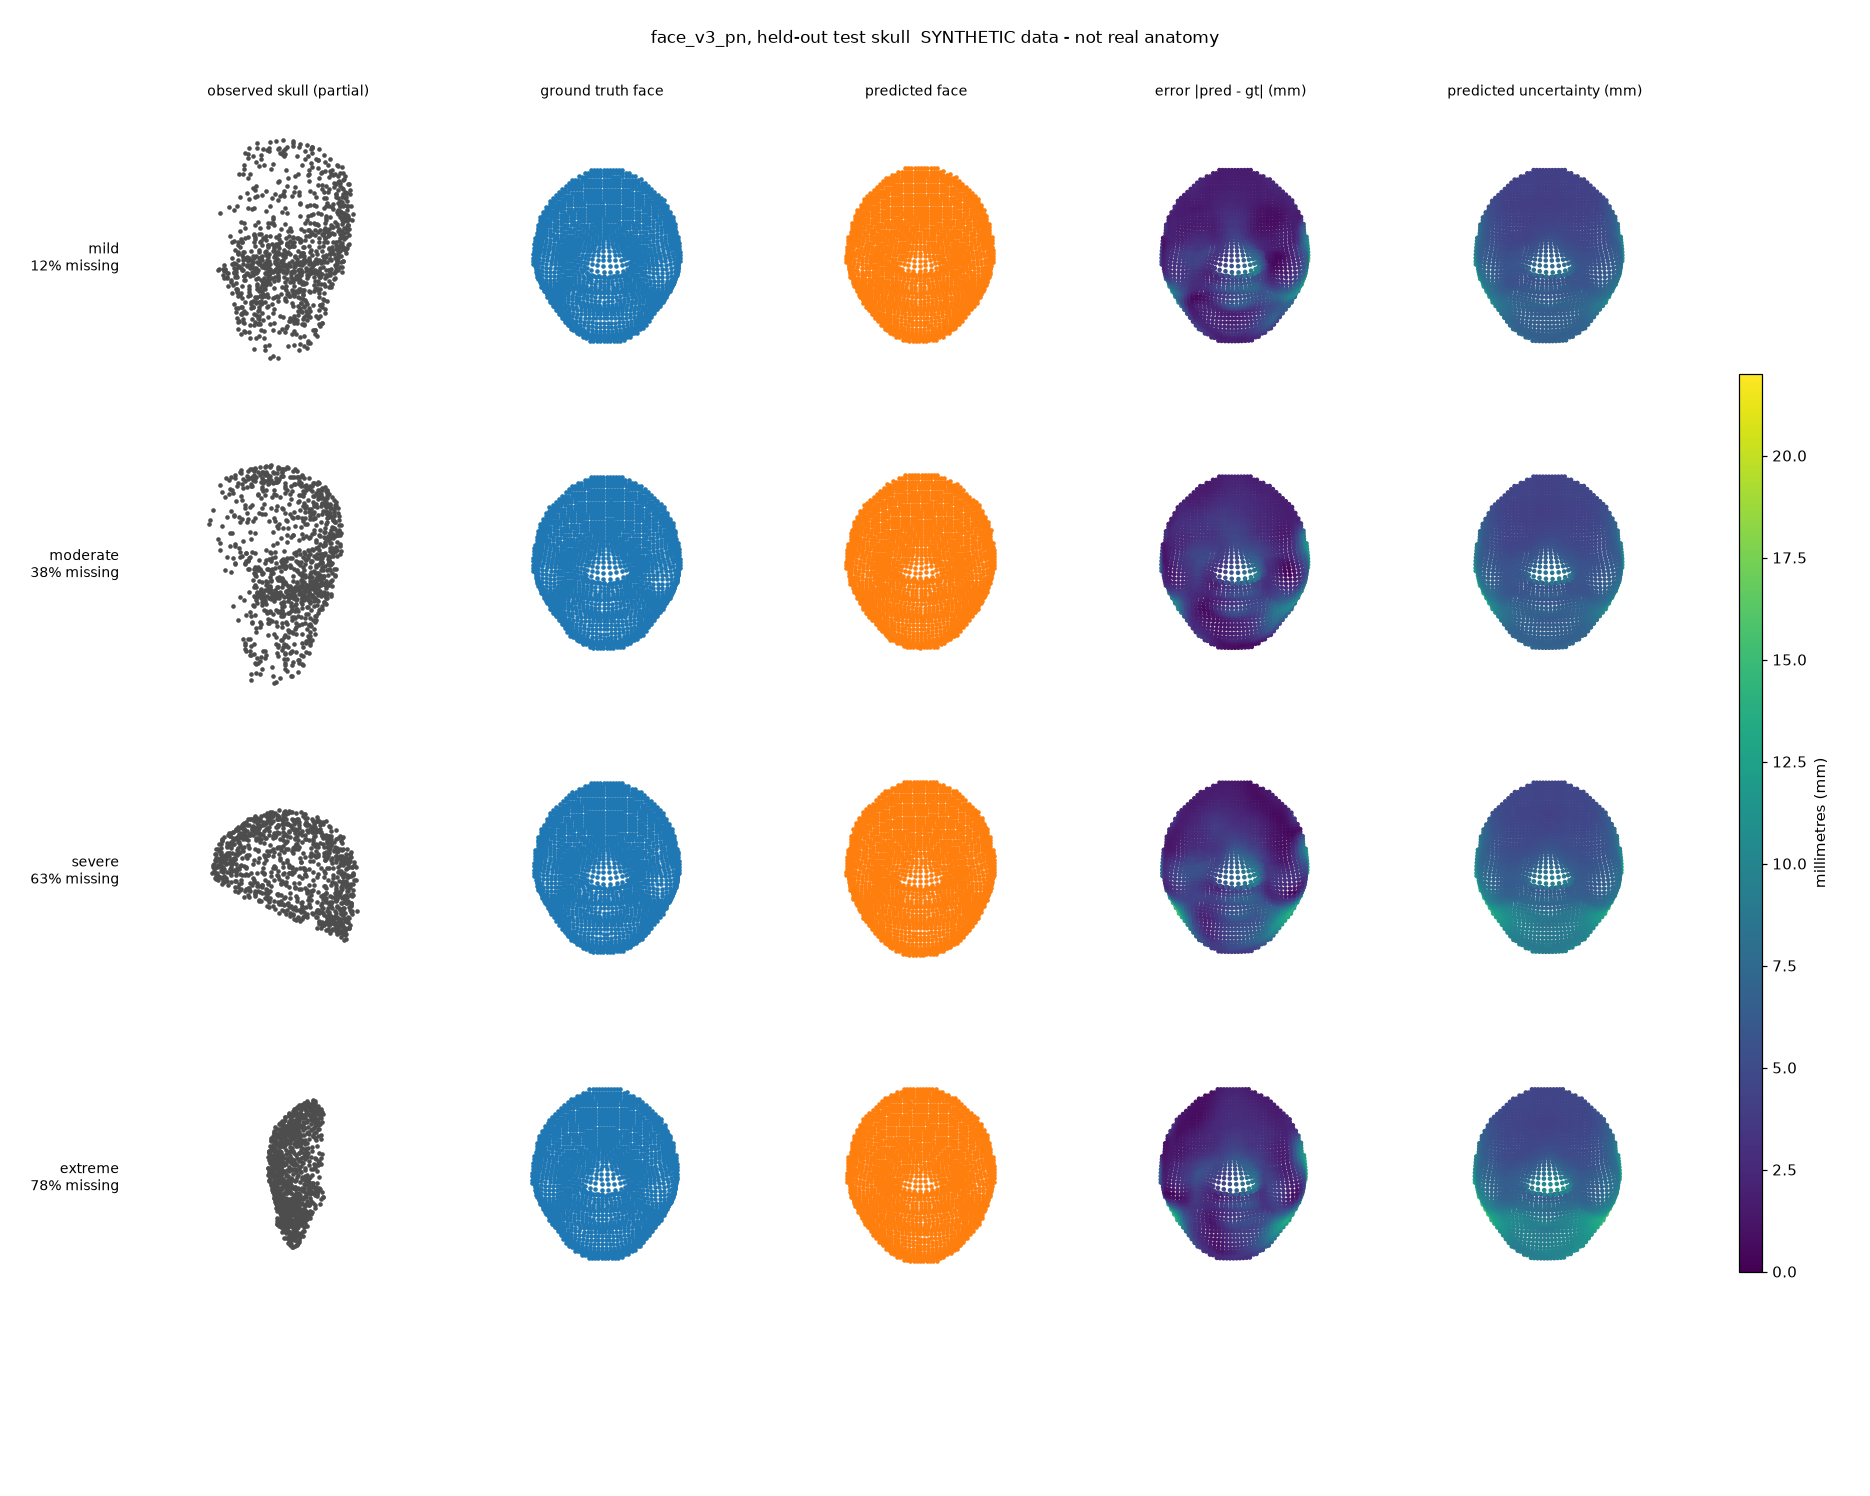

In [2]:
from src.visualization.results import load_run, predict_sample, pick_by_severity, reconstruction_figure
from src.data import dataset as ds
model, norm, cfg, root = load_run(RUN)
d = ds.UncertafaceDataset(root, 'test', norm, cfg['data']['n_points'], cfg['data']['knn_k'], cache=False)
idx = pick_by_severity(d); preds = {s: predict_sample(model, norm, d, i) for s, i in idx.items()}
summ = reconstruction_figure(preds, 'reports/reconstruction_test.png', 'face_v3_pn, held-out test skull')
print({s: {k: round(v, 2) for k, v in x.items() if isinstance(v, float)} for s, x in summ.items()})
from IPython.display import Image, display; display(Image('reports/reconstruction_test.png'))

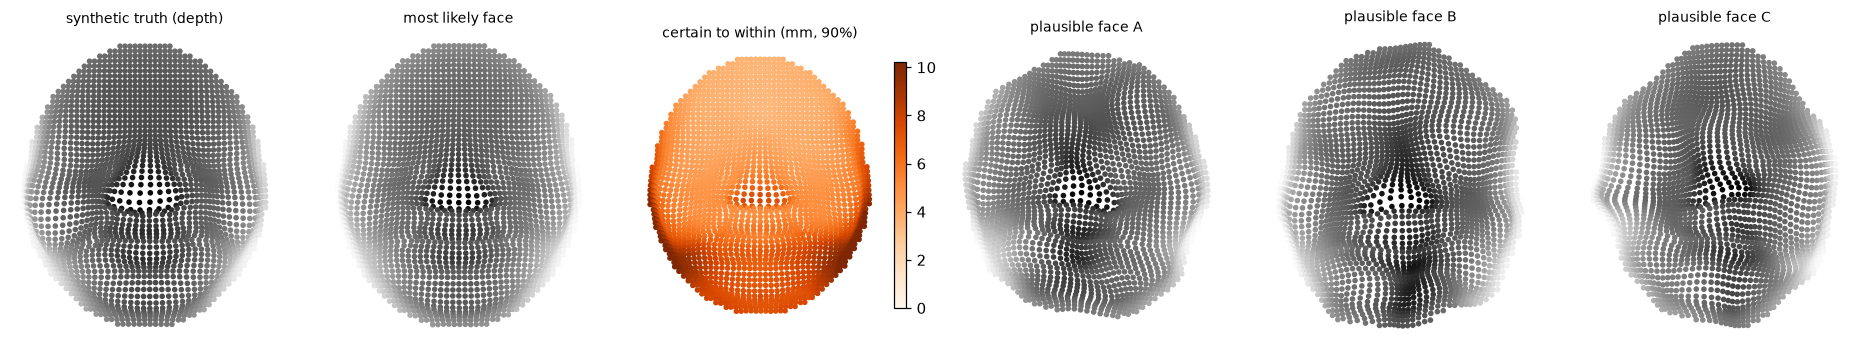

In [3]:
%matplotlib inline
from src.uncertainty import plausible_faces as pf
from src.uncertainty.calibration import ConformalCalibrator
from src.evaluation.predict import collect
o = collect(model, norm, d, 'cpu')
i = idx['severe']
q90 = float(ConformalCalibrator.load(RES + '/calibrator_global.json').scale(0.9, o['mean'].shape))
tpl = norm.inverse(model.decoder.template.cpu().numpy())
W = pf.smoothing_matrix(tpl[:, [0, 2]], 12.0)
samples = pf.sample_faces(o['mean'][i], o['std'][i], W, q90, 4, seed=1)
hw = q90 * np.sqrt((o['std'][i] ** 2).mean(-1))
fig, ax = plt.subplots(1, 6, figsize=(17, 3.6))
def face(a, v, c, title, cmap='Greys', vmin=None, vmax=None):
    s = a.scatter(v[:, 0], v[:, 2], s=7, c=c, cmap=cmap, vmin=vmin, vmax=vmax); a.set_aspect('equal'); a.set_title(title, fontsize=9); a.axis('off'); return s
face(ax[0], o['gt'][i], o['gt'][i][:, 1], 'synthetic truth (depth)')
face(ax[1], o['mean'][i], o['mean'][i][:, 1], 'most likely face')
s = face(ax[2], o['mean'][i], hw, 'certain to within (mm, 90%)', 'Oranges', 0, float(np.quantile(hw, .98))); plt.colorbar(s, ax=ax[2], fraction=.046)
for k in range(3): face(ax[3 + k], samples[k], samples[k][:, 1], f'plausible face {"ABC"[k]}')
plt.tight_layout(); plt.show()

In [4]:
zone = pf.zone_ids(tpl[:, 0], tpl[:, 2])
spread = np.linalg.norm(samples.std(0), axis=1)
rows = pf.zone_table(zone, hw, spread)
err = np.linalg.norm(o['mean'][i] - o['gt'][i], axis=1)
print(f"{'region':14s} {'+- half-width mm':>17} {'faces differ mm':>16} {'actual error mm':>16}")
for r_ in rows: print(f"{r_['zone']:14s} {r_['halfwidth_mm']:17.1f} {r_['sample_spread_mm']:16.1f} {err[zone == pf.ZONES.index(r_['zone'])].mean():16.1f}")

region          +- half-width mm  faces differ mm  actual error mm
forehead                     4.0              3.6              2.3
eyes                         5.1              5.0              4.1
nose                         5.5              4.8              5.9
cheeks                       6.0              5.1              4.4
mouth                        7.2              5.8              7.0
chin and jaw                 8.0              6.0              7.0


In [5]:
z = json.load(open(RES + '/zone_certainty.json'))
print('over all', z['n_test'], 'test views: region rank correlation (certainty vs real error) =', round(z['zone_rank_spearman_halfwidth_vs_error'], 2))
print('error in the 25%% most / least certain points: %.2f / %.2f mm' % (z['error_in_25pct_most_certain_mm'], z['error_in_25pct_least_certain_mm']))
print('shown half-widths contain %.1f%% of true coordinates (target 90)' % (100 * z['coverage_per_coordinate_inside_halfwidth']))
print('samples: mean sample RMSE %.2f mm vs mean prediction %.2f mm; best-of-%d (oracle) %.2f mm' % (z['samples']['mean_sample_rmse_mm'], z['samples']['mean_prediction_rmse_mm'], z['k'], z['samples']['best_of_k_rmse_mm']))
print('The plausible faces illustrate the size of the uncertainty. They are not better guesses than the most likely face.')

over all 48 test views: region rank correlation (certainty vs real error) = 1.0
error in the 25% most / least certain points: 2.82 / 7.60 mm
shown half-widths contain 90.7% of true coordinates (target 90)
samples: mean sample RMSE 8.37 mm vs mean prediction 5.86 mm; best-of-4 (oracle) 7.47 mm
The plausible faces illustrate the size of the uncertainty. They are not better guesses than the most likely face.
